In [13]:
import fuzzywuzzy
from fuzzywuzzy import process
import pandas as pd
import numpy as np
np.random.seed(0)

In [14]:
profs = pd.read_csv('pakistan_intellectual_capital.csv')

In [15]:
countries = profs['Country'].unique()
countries.sort()
countries

array([' Germany', ' New Zealand', ' Sweden', ' USA', 'Australia',
       'Austria', 'Canada', 'China', 'Finland', 'France', 'Greece',
       'HongKong', 'Ireland', 'Italy', 'Japan', 'Macau', 'Malaysia',
       'Mauritius', 'Netherland', 'New Zealand', 'Norway', 'Pakistan',
       'Portugal', 'Russian Federation', 'Saudi Arabia', 'Scotland',
       'Singapore', 'South Korea', 'SouthKorea', 'Spain', 'Sweden',
       'Thailand', 'Turkey', 'UK', 'USA', 'USofA', 'Urbana', 'germany'],
      dtype=object)

In [16]:
profs.Country = profs.Country.str.lower()
profs.Country = profs.Country.str.strip()

In [17]:
countries = profs['Country'].unique()
countries.sort()
countries

array(['australia', 'austria', 'canada', 'china', 'finland', 'france',
       'germany', 'greece', 'hongkong', 'ireland', 'italy', 'japan',
       'macau', 'malaysia', 'mauritius', 'netherland', 'new zealand',
       'norway', 'pakistan', 'portugal', 'russian federation',
       'saudi arabia', 'scotland', 'singapore', 'south korea',
       'southkorea', 'spain', 'sweden', 'thailand', 'turkey', 'uk',
       'urbana', 'usa', 'usofa'], dtype=object)

In [18]:
matches = fuzzywuzzy.process.extract("south korea", countries, limit=10, scorer=fuzzywuzzy.fuzz.token_sort_ratio)
matches

[('south korea', 100),
 ('southkorea', 48),
 ('saudi arabia', 43),
 ('norway', 35),
 ('austria', 33),
 ('ireland', 33),
 ('pakistan', 32),
 ('portugal', 32),
 ('scotland', 32),
 ('australia', 30)]

In [19]:
close_matches = [matches[0] for matches in matches if matches[1] >= 47]
close_matches

['south korea', 'southkorea']

In [20]:
rows_with_matches = profs.Country.isin(close_matches)
rows_with_matches

0       False
1       False
2       False
3       False
4       False
        ...  
1137     True
1138    False
1139    False
1140    False
1141     True
Name: Country, Length: 1142, dtype: bool

In [21]:
profs.Country.loc[rows_with_matches]

33       southkorea
163      southkorea
169      southkorea
177      southkorea
189      southkorea
244      southkorea
321      southkorea
489     south korea
677     south korea
685     south korea
764     south korea
906     south korea
931     south korea
1137    south korea
1141    south korea
Name: Country, dtype: object

In [22]:
profs.loc[rows_with_matches, "Country"] = "south korea"

In [23]:
profs.Country.unique()

array(['thailand', 'pakistan', 'germany', 'austria', 'australia', 'uk',
       'china', 'france', 'usofa', 'south korea', 'malaysia', 'sweden',
       'italy', 'canada', 'norway', 'ireland', 'new zealand', 'urbana',
       'portugal', 'russian federation', 'usa', 'finland', 'netherland',
       'greece', 'turkey', 'macau', 'singapore', 'spain', 'japan',
       'hongkong', 'saudi arabia', 'mauritius', 'scotland'], dtype=object)

In [24]:
def replace_matches_in_column(df, column, string_to_match, min_ratio = 47):
    strings = df[column].unique()
    matches = fuzzywuzzy.process.extract(string_to_match, strings, min_ratio, limit=10)
    close_matches = [matches[0] for matches in matches if matches[1] >= min_ratio ]
    rows_with_matches = df[column].isin(close_matches)
    df.loc[rows_with_matches, column] = string_to_match
    print("All done")

In [25]:
profs.columns

Index(['Unnamed: 0', 'S#', 'Teacher Name', 'University Currently Teaching',
       'Department', 'Province University Located', 'Designation',
       'Terminal Degree', 'Graduated from', 'Country', 'Year',
       'Area of Specialization/Research Interests', 'Other Information'],
      dtype='object')

In [26]:
profs["Graduated from"].unique()

array(['Asian Institute of Technology',
       'Balochistan University of Information Technology, Engineering and Management Sciences',
       'University of Balochistan',
       "Sardar Bahadur Khan Women's University",
       'SRH Hochschule Heidelberg',
       'Institute of Business Administration,Karachi', 'DUET,Karachi',
       'University of Turbat', 'University of Vienna',
       'Monash University', 'University of Stirling',
       'Chinese Academy of Sciences', 'University of Innsbruck',
       'Vienna University of Technology', 'University of Paris-Est',
       'The University of Cambridge', 'Harbin Institute of Technology',
       'University of Nice, Sophia Antipolis', 'The University of York',
       'Galilée - Université Paris 13', 'University of Bedfordshire',
       'North Dakota State University', 'Kyungpook National University',
       'The University of Manchester',
       'National University of Sciences and Technology',
       'FAST– National University of Computer

In [27]:
profs["Graduated from"].str.strip()

0                           Asian Institute of Technology
1                           Asian Institute of Technology
2                           Asian Institute of Technology
3                           Asian Institute of Technology
4       Balochistan University of Information Technolo...
                              ...                        
1137                                                  JNU
1138                                             Grenoble
1139                          Florida Atlantic University
1140    Ghulam Ishaq Khan Institute of Science and Tec...
1141                            Seoul National University
Name: Graduated from, Length: 1142, dtype: object

In [28]:
import numpy as np
import pandas as pd
np.random.seed(0)
x = np.random.rand(100) * 10
y=3*x+np.random.normal(0,3,100)
data = pd.DataFrame({'X':x, 'Y':y})
data.head()


,X,Y
0,5.488135,12.968956
1,7.151894,24.158160
2,6.027634,19.479889
3,5.448832,11.737764
4,4.236548,17.174401


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

In [30]:
X_train, X_test, y_train, y_test = train_test_split(data[["X"]], data["Y"], test_size=0.2, random_state=42)

In [31]:
model = LinearRegression()
model.fit(X_train, y_train)
yhat = model.predict(X_test)

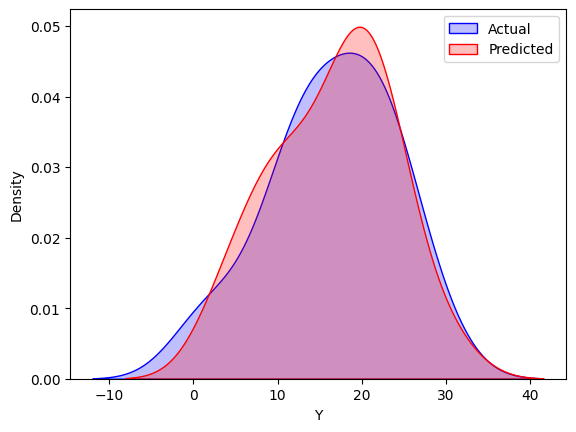

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.kdeplot(y_test, label="Actual", fill=True, color='blue')
sns.kdeplot(yhat, fill=True, label="Predicted", color='Red')
plt.legend()